In [1]:
!pip -q install ucimlrepo

In [2]:
from ucimlrepo import fetch_ucirepo

# Load the UCI Phishing Websites dataset
phishing = fetch_ucirepo(id=327)

# Extract features and labels
X = phishing.data.features
y = phishing.data.targets

print("Dataset Shape:", X.shape)
print("Target Shape:", y.shape)
print("\nFirst 5 Rows:")
print(X.head())

Dataset Shape: (11055, 30)
Target Shape: (11055, 1)

First 5 Rows:
   having_ip_address  url_length  shortining_service  having_at_symbol  \
0                 -1           1                   1                 1   
1                  1           1                   1                 1   
2                  1           0                   1                 1   
3                  1           0                   1                 1   
4                  1           0                  -1                 1   

   double_slash_redirecting  prefix_suffix  having_sub_domain  sslfinal_state  \
0                        -1             -1                 -1              -1   
1                         1             -1                  0               1   
2                         1             -1                 -1              -1   
3                         1             -1                 -1              -1   
4                         1             -1                  1               1   

 

In [3]:
import pandas as pd
import numpy as np

# Combine features and target
df = pd.concat([X, y], axis=1)

print("========== DATASET INFORMATION ==========")

print("\nDataset Shape:")
print(df.shape)

print("\nColumn Names:")
print(df.columns.tolist())

print("\nMissing Values:")
print(df.isnull().sum())

print("\nTarget Class Distribution:")
print(y.value_counts())

print("\nFirst 5 Rows:")
display(df.head())

========== DATASET INFORMATION ==========

Dataset Shape:
(11055, 31)

Column Names:
['having_ip_address', 'url_length', 'shortining_service', 'having_at_symbol', 'double_slash_redirecting', 'prefix_suffix', 'having_sub_domain', 'sslfinal_state', 'domain_registration_length', 'favicon', 'port', 'https_token', 'request_url', 'url_of_anchor', 'links_in_tags', 'sfh', 'submitting_to_email', 'abnormal_url', 'redirect', 'on_mouseover', 'rightclick', 'popupwindow', 'iframe', 'age_of_domain', 'dnsrecord', 'web_traffic', 'page_rank', 'google_index', 'links_pointing_to_page', 'statistical_report', 'result']

Missing Values:
having_ip_address             0
url_length                    0
shortining_service            0
having_at_symbol              0
double_slash_redirecting      0
prefix_suffix                 0
having_sub_domain             0
sslfinal_state                0
domain_registration_length    0
favicon                       0
port                          0
https_token               

,having_ip_address,url_length,shortining_service,having_at_symbol,double_slash_redirecting,prefix_suffix,having_sub_domain,sslfinal_state,domain_registration_length,favicon,...,popupwindow,iframe,age_of_domain,dnsrecord,web_traffic,page_rank,google_index,links_pointing_to_page,statistical_report,result
0,-1,1,1,1,-1,-1,-1,-1,-1,1,...,1,1,-1,-1,-1,-1,1,1,-1,-1
1,1,1,1,1,1,-1,0,1,-1,1,...,1,1,-1,-1,0,-1,1,1,1,-1
2,1,0,1,1,1,-1,-1,-1,-1,1,...,1,1,1,-1,1,-1,1,0,-1,-1
3,1,0,1,1,1,-1,-1,-1,1,1,...,1,1,-1,-1,1,-1,1,-1,1,-1
4,1,0,-1,1,1,-1,1,1,-1,1,...,-1,1,-1,-1,0,-1,1,1,1,1


In [4]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
import numpy as np

# Separate input features and target
X = df.drop(columns=['result'])
y = df['result']

# Convert labels:
# Phishing (-1) -> 1
# Legitimate (1) -> 0
y = y.map({-1: 1, 1: 0})

# Check label conversion
print("Target Distribution:")
print(y.value_counts())

# Split dataset: 80% training, 20% testing
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

# Scale features using training data only
scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

print("\nTraining Data Shape:", X_train_scaled.shape)
print("Testing Data Shape:", X_test_scaled.shape)

print("\nPreprocessing completed successfully!")

Target Distribution:
result
0    6157
1    4898
Name: count, dtype: int64

Training Data Shape: (8844, 30)
Testing Data Shape: (2211, 30)

Preprocessing completed successfully!


In [5]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report
)
import time

# Initialize Random Forest
rf_model = RandomForestClassifier(
    n_estimators=100,
    max_depth=15,
    random_state=42,
    n_jobs=-1
)

# Train the model
start_time = time.time()

rf_model.fit(X_train_scaled, y_train)

rf_training_time = time.time() - start_time

# Make predictions
rf_predictions = rf_model.predict(X_test_scaled)

# Calculate evaluation metrics
rf_accuracy = accuracy_score(y_test, rf_predictions)
rf_precision = precision_score(y_test, rf_predictions)
rf_recall = recall_score(y_test, rf_predictions)
rf_f1 = f1_score(y_test, rf_predictions)

# Display results
print("========== RANDOM FOREST RESULTS ==========")
print(f"Accuracy: {rf_accuracy * 100:.2f}%")
print(f"Precision: {rf_precision * 100:.2f}%")
print(f"Recall: {rf_recall * 100:.2f}%")
print(f"F1-Score: {rf_f1 * 100:.2f}%")
print(f"Training Time: {rf_training_time:.2f} seconds")

print("\nClassification Report:")
print(classification_report(
    y_test,
    rf_predictions,
    target_names=["Legitimate", "Phishing"]
))

print("\nConfusion Matrix:")
print(confusion_matrix(y_test, rf_predictions))

========== RANDOM FOREST RESULTS ==========
Accuracy: 97.01%
Precision: 97.41%
Recall: 95.82%
F1-Score: 96.60%
Training Time: 1.11 seconds

Classification Report:
              precision    recall  f1-score   support

  Legitimate       0.97      0.98      0.97      1231
    Phishing       0.97      0.96      0.97       980

    accuracy                           0.97      2211
   macro avg       0.97      0.97      0.97      2211
weighted avg       0.97      0.97      0.97      2211


Confusion Matrix:
[[1206   25]
 [  41  939]]


In [6]:
from sklearn.svm import SVC
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix
)
import time

# Initialize SVM
svm_model = SVC(
    kernel='rbf',
    C=1.0,
    gamma='scale',
    probability=True,
    random_state=42
)

# Train the model
start_time = time.time()

svm_model.fit(X_train_scaled, y_train)

svm_training_time = time.time() - start_time

# Make predictions
svm_predictions = svm_model.predict(X_test_scaled)

# Calculate evaluation metrics
svm_accuracy = accuracy_score(y_test, svm_predictions)
svm_precision = precision_score(y_test, svm_predictions)
svm_recall = recall_score(y_test, svm_predictions)
svm_f1 = f1_score(y_test, svm_predictions)

# Display results
print("========== SVM RESULTS ==========")
print(f"Accuracy: {svm_accuracy * 100:.2f}%")
print(f"Precision: {svm_precision * 100:.2f}%")
print(f"Recall: {svm_recall * 100:.2f}%")
print(f"F1-Score: {svm_f1 * 100:.2f}%")
print(f"Training Time: {svm_training_time:.2f} seconds")

print("\nClassification Report:")
print(classification_report(
    y_test,
    svm_predictions,
    target_names=["Legitimate", "Phishing"]
))

print("\nConfusion Matrix:")
print(confusion_matrix(y_test, svm_predictions))

========== SVM RESULTS ==========
Accuracy: 95.61%
Precision: 96.33%
Recall: 93.67%
F1-Score: 94.98%
Training Time: 11.69 seconds

Classification Report:
              precision    recall  f1-score   support

  Legitimate       0.95      0.97      0.96      1231
    Phishing       0.96      0.94      0.95       980

    accuracy                           0.96      2211
   macro avg       0.96      0.95      0.96      2211
weighted avg       0.96      0.96      0.96      2211


Confusion Matrix:
[[1196   35]
 [  62  918]]


In [7]:
import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense, Dropout, BatchNormalization
from tensorflow.keras.callbacks import EarlyStopping
from sklearn.model_selection import train_test_split
import numpy as np
import time

# Set random seeds for reproducibility
np.random.seed(42)
tf.random.set_seed(42)

# Create validation split from training data
X_dnn_train, X_dnn_val, y_dnn_train, y_dnn_val = train_test_split(
    X_train_scaled,
    y_train,
    test_size=0.20,
    random_state=42,
    stratify=y_train
)

# Build DNN architecture
dnn_model = Sequential([
    tf.keras.Input(shape=(30,)),

    Dense(128, activation='relu'),
    BatchNormalization(),
    Dropout(0.3),

    Dense(64, activation='relu'),
    BatchNormalization(),
    Dropout(0.2),

    Dense(32, activation='relu'),

    Dense(1, activation='sigmoid')
])

# Compile model
dnn_model.compile(
    optimizer='adam',
    loss='binary_crossentropy',
    metrics=['accuracy']
)

# Display model architecture
dnn_model.summary()

# Early stopping to prevent overfitting
early_stopping = EarlyStopping(
    monitor='val_loss',
    patience=8,
    restore_best_weights=True
)

# Train model
start_time = time.time()

dnn_history = dnn_model.fit(
    X_dnn_train,
    y_dnn_train,
    validation_data=(X_dnn_val, y_dnn_val),
    epochs=50,
    batch_size=32,
    callbacks=[early_stopping],
    verbose=1
)

dnn_training_time = time.time() - start_time

print("\nDNN Training Completed!")
print(f"Training Time: {dnn_training_time:.2f} seconds")

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 128)            │         3,968 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 128)            │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 64)             │         8,256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_1           │ (None, 64)             │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 32)             │         2,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 1)              │            33 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 15,105 (59.00 KB)

 Trainable params: 14,721 (57.50 KB)

 Non-trainable params: 384 (1.50 KB)

Epoch 1/50
222/222 ━━━━━━━━━━━━━━━━━━━━ 5s 4ms/step - accuracy: 0.8596 - loss: 0.3156 - val_accuracy: 0.9310 - val_loss: 0.1918
Epoch 2/50
222/222 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - accuracy: 0.9196 - loss: 0.2006 - val_accuracy: 0.9406 - val_loss: 0.1623
Epoch 3/50
222/222 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - accuracy: 0.9312 - loss: 0.1725 - val_accuracy: 0.9429 - val_loss: 0.1506
Epoch 4/50
222/222 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.9340 - loss: 0.1595 - val_accuracy: 0.9429 - val_loss: 0.1462
Epoch 5/50
222/222 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.9346 - loss: 0.1506 - val_accuracy: 0.9463 - val_loss: 0.1428
Epoch 6/50
222/222 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.9401 - loss: 0.1462 - val_accuracy: 0.9457 - val_loss: 0.1368
Epoch 7/50
222/222 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.9443 - loss: 0.1331 - val_accuracy: 0.9480 - val_loss: 0.1326
Epoch 8/50
222/222 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - accuracy: 0.9467 - loss: 0.1302 - val_accuracy: 0.

In [8]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix
)
import numpy as np

# Predict probabilities on test data
dnn_probabilities = dnn_model.predict(
    X_test_scaled,
    verbose=0
).flatten()

# Convert probabilities into binary predictions
dnn_predictions = (dnn_probabilities >= 0.5).astype(int)

# Calculate evaluation metrics
dnn_accuracy = accuracy_score(y_test, dnn_predictions)
dnn_precision = precision_score(y_test, dnn_predictions)
dnn_recall = recall_score(y_test, dnn_predictions)
dnn_f1 = f1_score(y_test, dnn_predictions)

print("========== DNN RESULTS ==========")

print(f"Accuracy: {dnn_accuracy * 100:.2f}%")
print(f"Precision: {dnn_precision * 100:.2f}%")
print(f"Recall: {dnn_recall * 100:.2f}%")
print(f"F1-Score: {dnn_f1 * 100:.2f}%")
print(f"Training Time: {dnn_training_time:.2f} seconds")

print("\nClassification Report:")
print(classification_report(
    y_test,
    dnn_predictions,
    target_names=["Legitimate", "Phishing"]
))

print("\nConfusion Matrix:")
print(confusion_matrix(y_test, dnn_predictions))

========== DNN RESULTS ==========
Accuracy: 96.02%
Precision: 96.46%
Recall: 94.49%
F1-Score: 95.46%
Training Time: 34.14 seconds

Classification Report:
              precision    recall  f1-score   support

  Legitimate       0.96      0.97      0.96      1231
    Phishing       0.96      0.94      0.95       980

    accuracy                           0.96      2211
   macro avg       0.96      0.96      0.96      2211
weighted avg       0.96      0.96      0.96      2211


Confusion Matrix:
[[1197   34]
 [  54  926]]


In [9]:
# ============================================
# ALGORITHM 4: 1D CONVOLUTIONAL NEURAL NETWORK
# ============================================

import tensorflow as tf
import numpy as np
import time

from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import (
    Input,
    Conv1D,
    BatchNormalization,
    MaxPooling1D,
    GlobalMaxPooling1D,
    Dense,
    Dropout
)
from tensorflow.keras.callbacks import EarlyStopping

# --------------------------------------------
# STEP 1: Set random seeds
# --------------------------------------------

np.random.seed(42)
tf.random.set_seed(42)

# --------------------------------------------
# STEP 2: Reshape dataset for CNN
# --------------------------------------------

# CNN expects 3D input:
# (samples, features, channels)

X_cnn_train = X_dnn_train.reshape(-1, 30, 1)
X_cnn_val = X_dnn_val.reshape(-1, 30, 1)
X_cnn_test = X_test_scaled.reshape(-1, 30, 1)

print("CNN Training Shape:", X_cnn_train.shape)
print("CNN Validation Shape:", X_cnn_val.shape)
print("CNN Testing Shape:", X_cnn_test.shape)

# --------------------------------------------
# STEP 3: Build CNN architecture
# --------------------------------------------

cnn_model = Sequential([

    Input(shape=(30, 1)),

    Conv1D(
        filters=32,
        kernel_size=3,
        activation='relu',
        padding='same'
    ),

    BatchNormalization(),

    MaxPooling1D(pool_size=2),

    Conv1D(
        filters=64,
        kernel_size=3,
        activation='relu',
        padding='same'
    ),

    GlobalMaxPooling1D(),

    Dense(32, activation='relu'),

    Dropout(0.3),

    Dense(1, activation='sigmoid')

])

# --------------------------------------------
# STEP 4: Compile CNN model
# --------------------------------------------

cnn_model.compile(
    optimizer='adam',
    loss='binary_crossentropy',
    metrics=['accuracy']
)

# --------------------------------------------
# STEP 5: Display model architecture
# --------------------------------------------

print("\n========== CNN ARCHITECTURE ==========")

cnn_model.summary()

# --------------------------------------------
# STEP 6: Early stopping
# --------------------------------------------

cnn_early_stopping = EarlyStopping(
    monitor='val_loss',
    patience=8,
    restore_best_weights=True
)

# --------------------------------------------
# STEP 7: Train CNN model
# --------------------------------------------

print("\n========== CNN TRAINING STARTED ==========")

start_time = time.time()

cnn_history = cnn_model.fit(
    X_cnn_train,
    y_dnn_train,
    validation_data=(X_cnn_val, y_dnn_val),
    epochs=50,
    batch_size=32,
    callbacks=[cnn_early_stopping],
    verbose=1
)

cnn_training_time = time.time() - start_time

# --------------------------------------------
# STEP 8: Display training results
# --------------------------------------------

print("\n========== CNN TRAINING COMPLETED ==========")

print(f"Training Time: {cnn_training_time:.2f} seconds")

print(
    f"Final Training Accuracy: "
    f"{cnn_history.history['accuracy'][-1] * 100:.2f}%"
)

print(
    f"Final Validation Accuracy: "
    f"{cnn_history.history['val_accuracy'][-1] * 100:.2f}%"
)

print(
    f"Best Validation Accuracy: "
    f"{max(cnn_history.history['val_accuracy']) * 100:.2f}%"
)

print(
    f"Total Epochs Completed: "
    f"{len(cnn_history.history['accuracy'])}"
)

CNN Training Shape: (7075, 30, 1)
CNN Validation Shape: (1769, 30, 1)
CNN Testing Shape: (2211, 30, 1)

========== CNN ARCHITECTURE ==========


Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv1d (Conv1D)                 │ (None, 30, 32)         │           128 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_2           │ (None, 30, 32)         │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling1d (MaxPooling1D)    │ (None, 15, 32)         │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv1d_1 (Conv1D)               │ (None, 15, 64)         │         6,208 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_max_pooling1d            │ (None, 64)             │             0 │
│ (GlobalMaxPooling1D)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_4 (Dense)                 │ (None, 32)             │         2,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_2 (Dropout)             │ (None, 32)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_5 (Dense)                 │ (None, 1)              │            33 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 8,577 (33.50 KB)

 Trainable params: 8,513 (33.25 KB)

 Non-trainable params: 64 (256.00 B)


========== CNN TRAINING STARTED ==========
Epoch 1/50
222/222 ━━━━━━━━━━━━━━━━━━━━ 9s 14ms/step - accuracy: 0.8137 - loss: 0.4097 - val_accuracy: 0.9028 - val_loss: 0.3976
Epoch 2/50
222/222 ━━━━━━━━━━━━━━━━━━━━ 3s 5ms/step - accuracy: 0.8991 - loss: 0.2475 - val_accuracy: 0.9192 - val_loss: 0.2228
Epoch 3/50
222/222 ━━━━━━━━━━━━━━━━━━━━ 1s 5ms/step - accuracy: 0.9156 - loss: 0.2069 - val_accuracy: 0.9203 - val_loss: 0.1993
Epoch 4/50
222/222 ━━━━━━━━━━━━━━━━━━━━ 1s 5ms/step - accuracy: 0.9265 - loss: 0.1858 - val_accuracy: 0.9248 - val_loss: 0.1783
Epoch 5/50
222/222 ━━━━━━━━━━━━━━━━━━━━ 1s 6ms/step - accuracy: 0.9319 - loss: 0.1713 - val_accuracy: 0.9231 - val_loss: 0.1795
Epoch 6/50
222/222 ━━━━━━━━━━━━━━━━━━━━ 2s 9ms/step - accuracy: 0.9384 - loss: 0.1595 - val_accuracy: 0.9209 - val_loss: 0.1857
Epoch 7/50
222/222 ━━━━━━━━━━━━━━━━━━━━ 2s 7ms/step - accuracy: 0.9409 - loss: 0.1478 - val_accuracy: 0.9231 - val_loss: 0.1741
Epoch 8/50
222/222 ━━━━━━━━━━━━━━━━━━━━ 1s 5ms/step - accur

In [10]:
# ============================================
# ALGORITHM 4: CNN TESTING AND EVALUATION
# ============================================

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix
)

import numpy as np

# STEP 1: Predict probabilities on test data
cnn_probabilities = cnn_model.predict(
    X_cnn_test,
    verbose=0
).flatten()

# STEP 2: Convert probabilities to binary predictions
cnn_predictions = (cnn_probabilities >= 0.5).astype(int)

# STEP 3: Calculate performance metrics
cnn_accuracy = accuracy_score(y_test, cnn_predictions)
cnn_precision = precision_score(y_test, cnn_predictions)
cnn_recall = recall_score(y_test, cnn_predictions)
cnn_f1 = f1_score(y_test, cnn_predictions)

# STEP 4: Display results
print("========== CNN TEST RESULTS ==========")

print(f"Accuracy: {cnn_accuracy * 100:.2f}%")
print(f"Precision: {cnn_precision * 100:.2f}%")
print(f"Recall: {cnn_recall * 100:.2f}%")
print(f"F1-Score: {cnn_f1 * 100:.2f}%")
print(f"Training Time: {cnn_training_time:.2f} seconds")

# STEP 5: Classification report
print("\n========== CLASSIFICATION REPORT ==========")

print(
    classification_report(
        y_test,
        cnn_predictions,
        target_names=["Legitimate", "Phishing"]
    )
)

# STEP 6: Confusion matrix
print("\n========== CONFUSION MATRIX ==========")

print(confusion_matrix(y_test, cnn_predictions))

========== CNN TEST RESULTS ==========
Accuracy: 95.16%
Precision: 93.26%
Recall: 96.02%
F1-Score: 94.62%
Training Time: 39.27 seconds

========== CLASSIFICATION REPORT ==========
              precision    recall  f1-score   support

  Legitimate       0.97      0.94      0.96      1231
    Phishing       0.93      0.96      0.95       980

    accuracy                           0.95      2211
   macro avg       0.95      0.95      0.95      2211
weighted avg       0.95      0.95      0.95      2211


========== CONFUSION MATRIX ==========
[[1163   68]
 [  39  941]]


In [11]:
!pip -q install ucimlrepo

from ucimlrepo import fetch_ucirepo
import pandas as pd

# Download dataset
phishing_data = fetch_ucirepo(id=967)

# Combine features and target
df = pd.concat(
    [
        phishing_data.data.features,
        phishing_data.data.targets
    ],
    axis=1
)

print("Dataset Shape:", df.shape)

print("\nColumn Names:")
print(df.columns.tolist())

print("\nFirst 5 Records:")
display(df.head())

print("\nMissing Values:")
print(df.isnull().sum())

Dataset Shape: (235795, 55)

Column Names:
['URL', 'URLLength', 'Domain', 'DomainLength', 'IsDomainIP', 'TLD', 'URLSimilarityIndex', 'CharContinuationRate', 'TLDLegitimateProb', 'URLCharProb', 'TLDLength', 'NoOfSubDomain', 'HasObfuscation', 'NoOfObfuscatedChar', 'ObfuscationRatio', 'NoOfLettersInURL', 'LetterRatioInURL', 'NoOfDegitsInURL', 'DegitRatioInURL', 'NoOfEqualsInURL', 'NoOfQMarkInURL', 'NoOfAmpersandInURL', 'NoOfOtherSpecialCharsInURL', 'SpacialCharRatioInURL', 'IsHTTPS', 'LineOfCode', 'LargestLineLength', 'HasTitle', 'Title', 'DomainTitleMatchScore', 'URLTitleMatchScore', 'HasFavicon', 'Robots', 'IsResponsive', 'NoOfURLRedirect', 'NoOfSelfRedirect', 'HasDescription', 'NoOfPopup', 'NoOfiFrame', 'HasExternalFormSubmit', 'HasSocialNet', 'HasSubmitButton', 'HasHiddenFields', 'HasPasswordField', 'Bank', 'Pay', 'Crypto', 'HasCopyrightInfo', 'NoOfImage', 'NoOfCSS', 'NoOfJS', 'NoOfSelfRef', 'NoOfEmptyRef', 'NoOfExternalRef', 'label']

First 5 Records:


,URL,URLLength,Domain,DomainLength,IsDomainIP,TLD,URLSimilarityIndex,CharContinuationRate,TLDLegitimateProb,URLCharProb,...,Pay,Crypto,HasCopyrightInfo,NoOfImage,NoOfCSS,NoOfJS,NoOfSelfRef,NoOfEmptyRef,NoOfExternalRef,label
0,https://www.southbankmosaics.com,31,www.southbankmosaics.com,24,0,com,100.0,1.000000,0.522907,0.061933,...,0,0,1,34,20,28,119,0,124,1
1,https://www.uni-mainz.de,23,www.uni-mainz.de,16,0,de,100.0,0.666667,0.032650,0.050207,...,0,0,1,50,9,8,39,0,217,1
2,https://www.voicefmradio.co.uk,29,www.voicefmradio.co.uk,22,0,uk,100.0,0.866667,0.028555,0.064129,...,0,0,1,10,2,7,42,2,5,1
3,https://www.sfnmjournal.com,26,www.sfnmjournal.com,19,0,com,100.0,1.000000,0.522907,0.057606,...,1,1,1,3,27,15,22,1,31,1
4,https://www.rewildingargentina.org,33,www.rewildingargentina.org,26,0,org,100.0,1.000000,0.079963,0.059441,...,1,0,1,244,15,34,72,1,85,1



Missing Values:
URL                           0
URLLength                     0
Domain                        0
DomainLength                  0
IsDomainIP                    0
TLD                           0
URLSimilarityIndex            0
CharContinuationRate          0
TLDLegitimateProb             0
URLCharProb                   0
TLDLength                     0
NoOfSubDomain                 0
HasObfuscation                0
NoOfObfuscatedChar            0
ObfuscationRatio              0
NoOfLettersInURL              0
LetterRatioInURL              0
NoOfDegitsInURL               0
DegitRatioInURL               0
NoOfEqualsInURL               0
NoOfQMarkInURL                0
NoOfAmpersandInURL            0
NoOfOtherSpecialCharsInURL    0
SpacialCharRatioInURL         0
IsHTTPS                       0
LineOfCode                    0
LargestLineLength             0
HasTitle                      0
Title                         0
DomainTitleMatchScore         0
URLTitleMatchScore     

In [12]:
# ==========================================
# STEP 2: DATASET INSPECTION
# ==========================================

print("Dataset Shape:", df.shape)

print("\n========== COLUMN NAMES ==========")
print(df.columns.tolist())

print("\n========== FIRST 5 ROWS ==========")
display(df.head())

print("\n========== POSSIBLE TARGET COLUMNS ==========")

for col in df.columns:
    if col.lower() in ["label", "class", "result", "target", "status"]:
        print(f"\nColumn: {col}")
        print(df[col].value_counts(dropna=False))

print("\n========== MISSING VALUES ==========")
print(df.isnull().sum()[df.isnull().sum() > 0])

Dataset Shape: (235795, 55)

========== COLUMN NAMES ==========
['URL', 'URLLength', 'Domain', 'DomainLength', 'IsDomainIP', 'TLD', 'URLSimilarityIndex', 'CharContinuationRate', 'TLDLegitimateProb', 'URLCharProb', 'TLDLength', 'NoOfSubDomain', 'HasObfuscation', 'NoOfObfuscatedChar', 'ObfuscationRatio', 'NoOfLettersInURL', 'LetterRatioInURL', 'NoOfDegitsInURL', 'DegitRatioInURL', 'NoOfEqualsInURL', 'NoOfQMarkInURL', 'NoOfAmpersandInURL', 'NoOfOtherSpecialCharsInURL', 'SpacialCharRatioInURL', 'IsHTTPS', 'LineOfCode', 'LargestLineLength', 'HasTitle', 'Title', 'DomainTitleMatchScore', 'URLTitleMatchScore', 'HasFavicon', 'Robots', 'IsResponsive', 'NoOfURLRedirect', 'NoOfSelfRedirect', 'HasDescription', 'NoOfPopup', 'NoOfiFrame', 'HasExternalFormSubmit', 'HasSocialNet', 'HasSubmitButton', 'HasHiddenFields', 'HasPasswordField', 'Bank', 'Pay', 'Crypto', 'HasCopyrightInfo', 'NoOfImage', 'NoOfCSS', 'NoOfJS', 'NoOfSelfRef', 'NoOfEmptyRef', 'NoOfExternalRef', 'label']

========== FIRST 5 ROWS ====

,URL,URLLength,Domain,DomainLength,IsDomainIP,TLD,URLSimilarityIndex,CharContinuationRate,TLDLegitimateProb,URLCharProb,...,Pay,Crypto,HasCopyrightInfo,NoOfImage,NoOfCSS,NoOfJS,NoOfSelfRef,NoOfEmptyRef,NoOfExternalRef,label
0,https://www.southbankmosaics.com,31,www.southbankmosaics.com,24,0,com,100.0,1.000000,0.522907,0.061933,...,0,0,1,34,20,28,119,0,124,1
1,https://www.uni-mainz.de,23,www.uni-mainz.de,16,0,de,100.0,0.666667,0.032650,0.050207,...,0,0,1,50,9,8,39,0,217,1
2,https://www.voicefmradio.co.uk,29,www.voicefmradio.co.uk,22,0,uk,100.0,0.866667,0.028555,0.064129,...,0,0,1,10,2,7,42,2,5,1
3,https://www.sfnmjournal.com,26,www.sfnmjournal.com,19,0,com,100.0,1.000000,0.522907,0.057606,...,1,1,1,3,27,15,22,1,31,1
4,https://www.rewildingargentina.org,33,www.rewildingargentina.org,26,0,org,100.0,1.000000,0.079963,0.059441,...,1,0,1,244,15,34,72,1,85,1



========== POSSIBLE TARGET COLUMNS ==========

Column: label
label
1    134850
0    100945
Name: count, dtype: int64

========== MISSING VALUES ==========
Series([], dtype: int64)


In [13]:
# ============================================
# STEP 3: RAW URL FEATURE EXTRACTION
# ============================================

import re
import ipaddress
import pandas as pd
from urllib.parse import urlsplit

def extract_url_features(url):
    url = str(url).strip()

    # Add a scheme only for parsing if one is missing
    parsed_url = url if "://" in url else "http://" + url
    parsed = urlsplit(parsed_url)

    hostname = (parsed.hostname or "").lower()
    path = parsed.path or ""
    query = parsed.query or ""

    # Check if hostname is an IP address
    try:
        ipaddress.ip_address(hostname)
        is_ip = 1
    except ValueError:
        is_ip = 0

    # Suspicious words
    suspicious_words = [
        "login", "verify", "secure", "account",
        "update", "bank", "signin", "password",
        "confirm", "payment", "wallet"
    ]

    url_lower = url.lower()

    features = {
        "url_length": len(url),
        "hostname_length": len(hostname),
        "path_length": len(path),
        "query_length": len(query),

        "dot_count": url.count("."),
        "hyphen_count": url.count("-"),
        "underscore_count": url.count("_"),
        "slash_count": url.count("/"),
        "question_mark_count": url.count("?"),
        "equal_count": url.count("="),
        "at_count": url.count("@"),
        "ampersand_count": url.count("&"),
        "percent_count": url.count("%"),

        "digit_count": sum(c.isdigit() for c in url),
        "letter_count": sum(c.isalpha() for c in url),

        "digit_ratio": sum(c.isdigit() for c in url) / max(len(url), 1),
        "letter_ratio": sum(c.isalpha() for c in url) / max(len(url), 1),

        "is_https": int(parsed.scheme.lower() == "https"),
        "is_ip_address": is_ip,

        "subdomain_count": max(len(hostname.split(".")) - 2, 0),

        "has_suspicious_word": int(
            any(word in url_lower for word in suspicious_words)
        ),

        "suspicious_word_count": sum(
            word in url_lower for word in suspicious_words
        ),

        "has_port": int(parsed.port is not None),

        "has_fragment": int(bool(parsed.fragment)),

        "has_query": int(bool(query))
    }

    return features

# Test feature extraction on one URL
sample_url = df["URL"].iloc[0]

print("Sample URL:", sample_url)
print("\nExtracted Features:")

display(pd.DataFrame([extract_url_features(sample_url)]))

Sample URL: https://www.southbankmosaics.com

Extracted Features:


,url_length,hostname_length,path_length,query_length,dot_count,hyphen_count,underscore_count,slash_count,question_mark_count,equal_count,...,digit_ratio,letter_ratio,is_https,is_ip_address,subdomain_count,has_suspicious_word,suspicious_word_count,has_port,has_fragment,has_query
0,32,24,0,0,2,0,0,2,0,0,...,0.0,0.84375,1,0,1,1,1,0,0,0


In [14]:
# ============================================
# STEP 4: PREPARE URL DATASET
# ============================================

import pandas as pd
import numpy as np
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

# Keep only URLs and labels
url_df = df[["URL", "label"]].copy()

# Remove missing URLs
url_df = url_df.dropna(subset=["URL", "label"])

# Remove duplicate URLs
url_df = url_df.drop_duplicates(subset=["URL"])

print("Unique URLs:", len(url_df))

# Convert target labels:
# Original: 1 = Legitimate, 0 = Phishing
# New:      0 = Legitimate, 1 = Phishing
url_df["target"] = (url_df["label"] == 0).astype(int)

# Extract features from every URL
print("\nExtracting URL features...")

X_url = pd.DataFrame(
    [extract_url_features(url) for url in url_df["URL"]],
    index=url_df.index
)

y_url = url_df["target"]

print("\nFeature extraction completed!")
print("Feature Matrix Shape:", X_url.shape)

print("\nTarget Distribution:")
print(y_url.value_counts())

# Split data: 80% training, 20% testing
X_train_url, X_test_url, y_train_url, y_test_url = train_test_split(
    X_url,
    y_url,
    test_size=0.20,
    random_state=42,
    stratify=y_url
)

# Scale using training data only
url_scaler = StandardScaler()

X_train_url_scaled = url_scaler.fit_transform(X_train_url)
X_test_url_scaled = url_scaler.transform(X_test_url)

print("\n========== FINAL DATASET SHAPES ==========")
print("Training:", X_train_url_scaled.shape)
print("Testing:", X_test_url_scaled.shape)

print("\n========== FEATURE NAMES ==========")
print(X_url.columns.tolist())

print("\nDataset preparation completed successfully!")

Unique URLs: 235370

Extracting URL features...

Feature extraction completed!
Feature Matrix Shape: (235370, 25)

Target Distribution:
target
0    134850
1    100520
Name: count, dtype: int64

========== FINAL DATASET SHAPES ==========
Training: (188296, 25)
Testing: (47074, 25)

========== FEATURE NAMES ==========
['url_length', 'hostname_length', 'path_length', 'query_length', 'dot_count', 'hyphen_count', 'underscore_count', 'slash_count', 'question_mark_count', 'equal_count', 'at_count', 'ampersand_count', 'percent_count', 'digit_count', 'letter_count', 'digit_ratio', 'letter_ratio', 'is_https', 'is_ip_address', 'subdomain_count', 'has_suspicious_word', 'suspicious_word_count', 'has_port', 'has_fragment', 'has_query']

Dataset preparation completed successfully!


In [15]:
# ============================================
# STEP 5: RANDOM FOREST - URL PHISHING DETECTION
# ============================================

import time

from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix
)

# Create Random Forest model
rf_url_model = RandomForestClassifier(
    n_estimators=100,
    max_depth=15,
    random_state=42,
    n_jobs=-1
)

# Train model
print("Training Random Forest...")

start_time = time.time()

rf_url_model.fit(X_train_url, y_train_url)

rf_url_training_time = time.time() - start_time

# Predict on test dataset
rf_url_predictions = rf_url_model.predict(X_test_url)

# Calculate metrics
rf_url_accuracy = accuracy_score(y_test_url, rf_url_predictions)
rf_url_precision = precision_score(y_test_url, rf_url_predictions)
rf_url_recall = recall_score(y_test_url, rf_url_predictions)
rf_url_f1 = f1_score(y_test_url, rf_url_predictions)

# Display results
print("\n========== RANDOM FOREST RESULTS ==========")

print(f"Accuracy: {rf_url_accuracy * 100:.2f}%")
print(f"Precision: {rf_url_precision * 100:.2f}%")
print(f"Recall: {rf_url_recall * 100:.2f}%")
print(f"F1-Score: {rf_url_f1 * 100:.2f}%")
print(f"Training Time: {rf_url_training_time:.2f} seconds")

print("\n========== CLASSIFICATION REPORT ==========")
print(
    classification_report(
        y_test_url,
        rf_url_predictions,
        target_names=["Legitimate", "Phishing"]
    )
)

print("\n========== CONFUSION MATRIX ==========")
print(confusion_matrix(y_test_url, rf_url_predictions))

Training Random Forest...

========== RANDOM FOREST RESULTS ==========
Accuracy: 99.58%
Precision: 99.89%
Recall: 99.11%
F1-Score: 99.50%
Training Time: 15.09 seconds

========== CLASSIFICATION REPORT ==========
              precision    recall  f1-score   support

  Legitimate       0.99      1.00      1.00     26970
    Phishing       1.00      0.99      1.00     20104

    accuracy                           1.00     47074
   macro avg       1.00      1.00      1.00     47074
weighted avg       1.00      1.00      1.00     47074


========== CONFUSION MATRIX ==========
[[26949    21]
 [  179 19925]]


In [16]:
# ============================================
# STEP 5.1: DATA LEAKAGE CHECK
# ============================================

import pandas as pd

# Convert feature sets to DataFrames
train_features = pd.DataFrame(
    X_train_url,
    columns=X_url.columns
)

test_features = pd.DataFrame(
    X_test_url,
    columns=X_url.columns
)

# Find identical feature combinations across splits
train_feature_patterns = set(
    map(tuple, train_features.to_numpy())
)

test_feature_patterns = list(
    map(tuple, test_features.to_numpy())
)

matching_patterns = sum(
    pattern in train_feature_patterns
    for pattern in test_feature_patterns
)

print("========== DATA LEAKAGE CHECK ==========")

print("Training samples:", len(train_features))
print("Testing samples:", len(test_features))

print(
    "Test samples with identical training feature vectors:",
    matching_patterns
)

print(
    "Percentage of test samples with matching feature vectors:",
    f"{matching_patterns / len(test_features) * 100:.2f}%"
)

# Check duplicates within the full feature dataset
duplicate_features = X_url.duplicated().sum()

print("\nDuplicate feature vectors in dataset:", duplicate_features)

# Check whether identical feature vectors have conflicting labels
feature_label_df = X_url.copy()
feature_label_df["target"] = y_url

conflicting_patterns = (
    feature_label_df
    .groupby(list(X_url.columns))["target"]
    .nunique()
    .gt(1)
    .sum()
)

print(
    "Feature patterns associated with conflicting labels:",
    conflicting_patterns
)

========== DATA LEAKAGE CHECK ==========
Training samples: 188296
Testing samples: 47074
Test samples with identical training feature vectors: 42624
Percentage of test samples with matching feature vectors: 90.55%

Duplicate feature vectors in dataset: 207300
Feature patterns associated with conflicting labels: 246


In [17]:
# ============================================
# STEP 5.2: SPLIT BY UNIQUE FEATURE PATTERNS
# ============================================

import numpy as np
import pandas as pd

from sklearn.model_selection import GroupShuffleSplit

# Group identical feature vectors together
feature_groups = pd.util.hash_pandas_object(
    X_url.reset_index(drop=True),
    index=False
)

# Prepare aligned data
X_clean = X_url.reset_index(drop=True)
y_clean = y_url.reset_index(drop=True)

# Split groups instead of individual rows
group_split = GroupShuffleSplit(
    n_splits=1,
    test_size=0.20,
    random_state=42
)

train_idx, test_idx = next(
    group_split.split(
        X_clean,
        y_clean,
        groups=feature_groups
    )
)

X_train_url = X_clean.iloc[train_idx]
X_test_url = X_clean.iloc[test_idx]

y_train_url = y_clean.iloc[train_idx]
y_test_url = y_clean.iloc[test_idx]

print("========== NEW DATASET SPLIT ==========")

print("Training samples:", len(X_train_url))
print("Testing samples:", len(X_test_url))

print("\nTraining class distribution:")
print(y_train_url.value_counts(normalize=True))

print("\nTesting class distribution:")
print(y_test_url.value_counts(normalize=True))

# Check overlapping feature patterns
train_patterns = set(
    map(tuple, X_train_url.to_numpy())
)

test_patterns = set(
    map(tuple, X_test_url.to_numpy())
)

overlap = len(train_patterns.intersection(test_patterns))

print("\nOverlapping feature patterns:", overlap)

# Scale data using training set only
from sklearn.preprocessing import StandardScaler

url_scaler = StandardScaler()

X_train_url_scaled = url_scaler.fit_transform(X_train_url)
X_test_url_scaled = url_scaler.transform(X_test_url)

print("\nTraining shape:", X_train_url_scaled.shape)
print("Testing shape:", X_test_url_scaled.shape)

========== NEW DATASET SPLIT ==========
Training samples: 182981
Testing samples: 52389

Training class distribution:
target
0    0.56313
1    0.43687
Name: proportion, dtype: float64

Testing class distribution:
target
0    0.60715
1    0.39285
Name: proportion, dtype: float64

Overlapping feature patterns: 0

Training shape: (182981, 25)
Testing shape: (52389, 25)


In [18]:
# ============================================
# STEP 5.3: RANDOM FOREST - IMPROVED DATA SPLIT
# ============================================

import time

from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report
)

# Create Random Forest model
rf_url_model = RandomForestClassifier(
    n_estimators=100,
    max_depth=15,
    random_state=42,
    n_jobs=-1
)

# Train Random Forest
print("Training Random Forest on improved dataset...")

start_time = time.time()

rf_url_model.fit(X_train_url, y_train_url)

rf_url_training_time = time.time() - start_time

# Predict on new test set
rf_url_predictions = rf_url_model.predict(X_test_url)

# Calculate performance
rf_url_accuracy = accuracy_score(y_test_url, rf_url_predictions)
rf_url_precision = precision_score(y_test_url, rf_url_predictions)
rf_url_recall = recall_score(y_test_url, rf_url_predictions)
rf_url_f1 = f1_score(y_test_url, rf_url_predictions)

# Display results
print("\n========== UPDATED RANDOM FOREST RESULTS ==========")

print(f"Accuracy: {rf_url_accuracy * 100:.2f}%")
print(f"Precision: {rf_url_precision * 100:.2f}%")
print(f"Recall: {rf_url_recall * 100:.2f}%")
print(f"F1-Score: {rf_url_f1 * 100:.2f}%")
print(f"Training Time: {rf_url_training_time:.2f} seconds")

print("\nClassification Report:")
print(
    classification_report(
        y_test_url,
        rf_url_predictions,
        target_names=["Legitimate", "Phishing"]
    )
)

print("\nConfusion Matrix:")
print(confusion_matrix(y_test_url, rf_url_predictions))

Training Random Forest on improved dataset...

========== UPDATED RANDOM FOREST RESULTS ==========
Accuracy: 99.38%
Precision: 99.90%
Recall: 98.52%
F1-Score: 99.21%
Training Time: 14.54 seconds

Classification Report:
              precision    recall  f1-score   support

  Legitimate       0.99      1.00      0.99     31808
    Phishing       1.00      0.99      0.99     20581

    accuracy                           0.99     52389
   macro avg       0.99      0.99      0.99     52389
weighted avg       0.99      0.99      0.99     52389


Confusion Matrix:
[[31788    20]
 [  304 20277]]


In [19]:
# ============================================
# STEP 5.4: DOMAIN OVERLAP CHECK
# ============================================

from urllib.parse import urlsplit
import pandas as pd

def get_hostname(url):
    url = str(url).strip()

    if "://" not in url:
        url = "http://" + url

    try:
        return (urlsplit(url).hostname or "").lower()
    except ValueError:
        return ""

# Recreate URL-to-feature alignment
url_records = url_df.reset_index(drop=True).copy()

# Check that rows remain aligned
assert len(url_records) == len(X_clean)

# Get URLs corresponding to each split
train_urls = url_records.iloc[train_idx]["URL"]
test_urls = url_records.iloc[test_idx]["URL"]

# Extract hostnames
train_hosts = train_urls.apply(get_hostname)
test_hosts = test_urls.apply(get_hostname)

# Find overlap
train_host_set = set(train_hosts)

overlap_count = test_hosts.isin(train_host_set).sum()

overlap_percentage = (
    overlap_count / len(test_hosts) * 100
)

print("========== DOMAIN OVERLAP CHECK ==========")

print("Training URLs:", len(train_urls))
print("Testing URLs:", len(test_urls))

print("Test URLs sharing a training hostname:", overlap_count)

print(
    f"Hostname overlap percentage: {overlap_percentage:.2f}%"
)

print("\nUnique training hostnames:", train_hosts.nunique())
print("Unique testing hostnames:", test_hosts.nunique())

========== DOMAIN OVERLAP CHECK ==========
Training URLs: 182981
Testing URLs: 52389
Test URLs sharing a training hostname: 3847
Hostname overlap percentage: 7.34%

Unique training hostnames: 171754
Unique testing hostnames: 50354


In [20]:
# STEP 5.5: FINAL DOMAIN-SEPARATED DATA SPLIT

!pip -q install tldextract

import pandas as pd
import tldextract

from sklearn.model_selection import GroupShuffleSplit
from sklearn.preprocessing import StandardScaler

extractor = tldextract.TLDExtract(suffix_list_urls=None)

def get_registered_domain(url):
    hostname = get_hostname(url)

    if not hostname:
        return ""

    extracted = extractor(hostname)

    return extracted.top_domain_under_public_suffix or hostname

# Prepare aligned data
url_records = url_df.reset_index(drop=True).copy()

X_clean = X_url.reset_index(drop=True)
y_clean = y_url.reset_index(drop=True)

# Extract registered domains
domain_groups = url_records["URL"].apply(get_registered_domain)

# Split by domain
domain_split = GroupShuffleSplit(
    n_splits=1,
    test_size=0.20,
    random_state=42
)

domain_train_idx, domain_test_idx = next(
    domain_split.split(
        X_clean,
        y_clean,
        groups=domain_groups
    )
)

# Training and testing data
X_train_url = X_clean.iloc[domain_train_idx].copy()
X_test_url = X_clean.iloc[domain_test_idx].copy()

y_train_url = y_clean.iloc[domain_train_idx].copy()
y_test_url = y_clean.iloc[domain_test_idx].copy()

# Scale features
url_scaler = StandardScaler()

X_train_url_scaled = url_scaler.fit_transform(X_train_url)
X_test_url_scaled = url_scaler.transform(X_test_url)

# Verify domain separation
train_domains = set(domain_groups.iloc[domain_train_idx])
test_domains = set(domain_groups.iloc[domain_test_idx])

print("========== FINAL DATASET SPLIT ==========")
print("Training samples:", len(X_train_url))
print("Testing samples:", len(X_test_url))
print("Overlapping domains:", len(train_domains & test_domains))

print("\nTraining class distribution:")
print(y_train_url.value_counts(normalize=True))

print("\nTesting class distribution:")
print(y_test_url.value_counts(normalize=True))

print("\nDataset ready for training!")

========== FINAL DATASET SPLIT ==========
Training samples: 193481
Testing samples: 41889
Overlapping domains: 0

Training class distribution:
target
0    0.557698
1    0.442302
Name: proportion, dtype: float64

Testing class distribution:
target
0    0.643272
1    0.356728
Name: proportion, dtype: float64

Dataset ready for training!


In [21]:
# ============================================
# FINAL MODEL 1: RANDOM FOREST
# ============================================

import time

from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report
)

# Initialize Random Forest
rf_url_model = RandomForestClassifier(
    n_estimators=100,
    max_depth=15,
    random_state=42,
    n_jobs=-1
)

# Train
print("Training Random Forest...")

start_time = time.time()

rf_url_model.fit(X_train_url, y_train_url)

rf_url_training_time = time.time() - start_time

# Predict
rf_url_predictions = rf_url_model.predict(X_test_url)

# Calculate metrics
rf_url_accuracy = accuracy_score(y_test_url, rf_url_predictions)
rf_url_precision = precision_score(y_test_url, rf_url_predictions)
rf_url_recall = recall_score(y_test_url, rf_url_predictions)
rf_url_f1 = f1_score(y_test_url, rf_url_predictions)

# Display results
print("\n========== FINAL RANDOM FOREST RESULTS ==========")

print(f"Accuracy: {rf_url_accuracy * 100:.2f}%")
print(f"Precision: {rf_url_precision * 100:.2f}%")
print(f"Recall: {rf_url_recall * 100:.2f}%")
print(f"F1-Score: {rf_url_f1 * 100:.2f}%")
print(f"Training Time: {rf_url_training_time:.2f} seconds")

print("\nClassification Report:")
print(
    classification_report(
        y_test_url,
        rf_url_predictions,
        target_names=["Legitimate", "Phishing"]
    )
)

print("\nConfusion Matrix:")
print(confusion_matrix(y_test_url, rf_url_predictions))

Training Random Forest...

========== FINAL RANDOM FOREST RESULTS ==========
Accuracy: 99.59%
Precision: 99.84%
Recall: 99.01%
F1-Score: 99.43%
Training Time: 18.77 seconds

Classification Report:
              precision    recall  f1-score   support

  Legitimate       0.99      1.00      1.00     26946
    Phishing       1.00      0.99      0.99     14943

    accuracy                           1.00     41889
   macro avg       1.00      0.99      1.00     41889
weighted avg       1.00      1.00      1.00     41889


Confusion Matrix:
[[26923    23]
 [  148 14795]]


In [22]:
# ============================================
# FINAL MODEL 2: SUPPORT VECTOR MACHINE (SVM)
# ============================================

import time

from sklearn.svm import LinearSVC
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report
)

# Initialize Linear SVM
svm_url_model = LinearSVC(
    C=1.0,
    max_iter=5000,
    random_state=42,
    dual=False
)

# Train
print("Training SVM...")

start_time = time.time()

svm_url_model.fit(X_train_url_scaled, y_train_url)

svm_url_training_time = time.time() - start_time

# Predict
svm_url_predictions = svm_url_model.predict(X_test_url_scaled)

# Calculate metrics
svm_url_accuracy = accuracy_score(y_test_url, svm_url_predictions)
svm_url_precision = precision_score(y_test_url, svm_url_predictions)
svm_url_recall = recall_score(y_test_url, svm_url_predictions)
svm_url_f1 = f1_score(y_test_url, svm_url_predictions)

# Display results
print("\n========== FINAL SVM RESULTS ==========")

print(f"Accuracy: {svm_url_accuracy * 100:.2f}%")
print(f"Precision: {svm_url_precision * 100:.2f}%")
print(f"Recall: {svm_url_recall * 100:.2f}%")
print(f"F1-Score: {svm_url_f1 * 100:.2f}%")
print(f"Training Time: {svm_url_training_time:.2f} seconds")

print("\nClassification Report:")
print(
    classification_report(
        y_test_url,
        svm_url_predictions,
        target_names=["Legitimate", "Phishing"]
    )
)

print("\nConfusion Matrix:")
print(confusion_matrix(y_test_url, svm_url_predictions))

Training SVM...

========== FINAL SVM RESULTS ==========
Accuracy: 99.38%
Precision: 99.98%
Recall: 98.29%
F1-Score: 99.13%
Training Time: 3.90 seconds

Classification Report:
              precision    recall  f1-score   support

  Legitimate       0.99      1.00      1.00     26946
    Phishing       1.00      0.98      0.99     14943

    accuracy                           0.99     41889
   macro avg       1.00      0.99      0.99     41889
weighted avg       0.99      0.99      0.99     41889


Confusion Matrix:
[[26943     3]
 [  256 14687]]


In [24]:
# ============================================
# FINAL MODEL 3: DEEP NEURAL NETWORK (DNN)
# ============================================

import time
import numpy as np
import tensorflow as tf

from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Input, Dense, Dropout
from tensorflow.keras.callbacks import EarlyStopping

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report
)

# Reproducibility
tf.keras.utils.set_random_seed(42)

# Build DNN
dnn_url_model = Sequential([
    Input(shape=(25,)),

    Dense(128, activation="relu"),
    Dropout(0.3),

    Dense(64, activation="relu"),
    Dropout(0.2),

    Dense(32, activation="relu"),

    Dense(1, activation="sigmoid")
])

# Compile
dnn_url_model.compile(
    optimizer="adam",
    loss="binary_crossentropy",
    metrics=["accuracy"]
)

# Stop training when validation loss stops improving
early_stop = EarlyStopping(
    monitor="val_loss",
    patience=5,
    restore_best_weights=True
)

print("Training DNN...")

start_time = time.time()

dnn_url_history = dnn_url_model.fit(
    X_train_url_scaled,
    y_train_url,
    validation_split=0.2,
    epochs=30,
    batch_size=256,
    callbacks=[early_stop],
    verbose=1
)

dnn_url_training_time = time.time() - start_time

# Predict on final test dataset
dnn_url_probabilities = dnn_url_model.predict(
    X_test_url_scaled,
    verbose=0
).ravel()

dnn_url_predictions = (
    dnn_url_probabilities >= 0.5
).astype(int)

# Calculate metrics
dnn_url_accuracy = accuracy_score(
    y_test_url, dnn_url_predictions
)

dnn_url_precision = precision_score(
    y_test_url, dnn_url_predictions
)

dnn_url_recall = recall_score(
    y_test_url, dnn_url_predictions
)

dnn_url_f1 = f1_score(
    y_test_url, dnn_url_predictions
)

# Display results
print("\n========== FINAL DNN RESULTS ==========")

print(f"Accuracy: {dnn_url_accuracy * 100:.2f}%")
print(f"Precision: {dnn_url_precision * 100:.2f}%")
print(f"Recall: {dnn_url_recall * 100:.2f}%")
print(f"F1-Score: {dnn_url_f1 * 100:.2f}%")
print(f"Training Time: {dnn_url_training_time:.2f} seconds")

print("\nClassification Report:")
print(
    classification_report(
        y_test_url,
        dnn_url_predictions,
        target_names=["Legitimate", "Phishing"]
    )
)

print("\nConfusion Matrix:")
print(
    confusion_matrix(y_test_url, dnn_url_predictions)
)

Training DNN...
Epoch 1/30
605/605 ━━━━━━━━━━━━━━━━━━━━ 8s 10ms/step - accuracy: 0.9822 - loss: 0.0572 - val_accuracy: 0.9946 - val_loss: 0.0229
Epoch 2/30
605/605 ━━━━━━━━━━━━━━━━━━━━ 9s 15ms/step - accuracy: 0.9946 - loss: 0.0237 - val_accuracy: 0.9947 - val_loss: 0.0225
Epoch 3/30
605/605 ━━━━━━━━━━━━━━━━━━━━ 9s 15ms/step - accuracy: 0.9948 - loss: 0.0230 - val_accuracy: 0.9946 - val_loss: 0.0225
Epoch 4/30
605/605 ━━━━━━━━━━━━━━━━━━━━ 4s 7ms/step - accuracy: 0.9949 - loss: 0.0229 - val_accuracy: 0.9952 - val_loss: 0.0221
Epoch 5/30
605/605 ━━━━━━━━━━━━━━━━━━━━ 3s 5ms/step - accuracy: 0.9949 - loss: 0.0228 - val_accuracy: 0.9952 - val_loss: 0.0220
Epoch 6/30
605/605 ━━━━━━━━━━━━━━━━━━━━ 3s 4ms/step - accuracy: 0.9950 - loss: 0.0225 - val_accuracy: 0.9951 - val_loss: 0.0221
Epoch 7/30
605/605 ━━━━━━━━━━━━━━━━━━━━ 4s 7ms/step - accuracy: 0.9951 - loss: 0.0222 - val_accuracy: 0.9953 - val_loss: 0.0221
Epoch 8/30
605/605 ━━━━━━━━━━━━━━━━━━━━ 3s 4ms/step - accuracy: 0.9951 - loss: 0.0222

In [25]:
# ============================================
# FINAL MODEL 4: 1D-CNN
# ============================================

import time
import numpy as np
import tensorflow as tf

from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import (
    Input,
    Conv1D,
    MaxPooling1D,
    Flatten,
    Dense,
    Dropout
)
from tensorflow.keras.callbacks import EarlyStopping

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report
)

# Reproducibility
tf.keras.utils.set_random_seed(42)

# Reshape 25 features for Conv1D
X_train_cnn = np.asarray(
    X_train_url_scaled, dtype=np.float32
).reshape(-1, 25, 1)

X_test_cnn = np.asarray(
    X_test_url_scaled, dtype=np.float32
).reshape(-1, 25, 1)

# Build CNN
cnn_url_model = Sequential([
    Input(shape=(25, 1)),

    Conv1D(64, kernel_size=3, activation="relu", padding="same"),
    MaxPooling1D(pool_size=2),

    Conv1D(128, kernel_size=3, activation="relu", padding="same"),
    MaxPooling1D(pool_size=2),

    Flatten(),

    Dense(64, activation="relu"),
    Dropout(0.3),

    Dense(1, activation="sigmoid")
])

# Compile
cnn_url_model.compile(
    optimizer="adam",
    loss="binary_crossentropy",
    metrics=["accuracy"]
)

early_stop_cnn = EarlyStopping(
    monitor="val_loss",
    patience=5,
    restore_best_weights=True
)

print("Training CNN...")

start_time = time.time()

cnn_url_history = cnn_url_model.fit(
    X_train_cnn,
    y_train_url,
    validation_split=0.2,
    epochs=30,
    batch_size=256,
    callbacks=[early_stop_cnn],
    verbose=1
)

cnn_url_training_time = time.time() - start_time

# Predict
cnn_url_probabilities = cnn_url_model.predict(
    X_test_cnn,
    verbose=0
).ravel()

cnn_url_predictions = (
    cnn_url_probabilities >= 0.5
).astype(int)

# Metrics
cnn_url_accuracy = accuracy_score(
    y_test_url, cnn_url_predictions
)

cnn_url_precision = precision_score(
    y_test_url, cnn_url_predictions
)

cnn_url_recall = recall_score(
    y_test_url, cnn_url_predictions
)

cnn_url_f1 = f1_score(
    y_test_url, cnn_url_predictions
)

# Results
print("\n========== FINAL CNN RESULTS ==========")

print(f"Accuracy: {cnn_url_accuracy * 100:.2f}%")
print(f"Precision: {cnn_url_precision * 100:.2f}%")
print(f"Recall: {cnn_url_recall * 100:.2f}%")
print(f"F1-Score: {cnn_url_f1 * 100:.2f}%")
print(f"Training Time: {cnn_url_training_time:.2f} seconds")

print("\nClassification Report:")
print(
    classification_report(
        y_test_url,
        cnn_url_predictions,
        target_names=["Legitimate", "Phishing"]
    )
)

print("\nConfusion Matrix:")
print(
    confusion_matrix(y_test_url, cnn_url_predictions)
)

Training CNN...
Epoch 1/30
605/605 ━━━━━━━━━━━━━━━━━━━━ 39s 59ms/step - accuracy: 0.9903 - loss: 0.0432 - val_accuracy: 0.9946 - val_loss: 0.0225
Epoch 2/30
605/605 ━━━━━━━━━━━━━━━━━━━━ 16s 26ms/step - accuracy: 0.9948 - loss: 0.0238 - val_accuracy: 0.9947 - val_loss: 0.0226
Epoch 3/30
605/605 ━━━━━━━━━━━━━━━━━━━━ 22s 28ms/step - accuracy: 0.9950 - loss: 0.0237 - val_accuracy: 0.9949 - val_loss: 0.0222
Epoch 4/30
605/605 ━━━━━━━━━━━━━━━━━━━━ 17s 27ms/step - accuracy: 0.9950 - loss: 0.0232 - val_accuracy: 0.9952 - val_loss: 0.0219
Epoch 5/30
605/605 ━━━━━━━━━━━━━━━━━━━━ 20s 27ms/step - accuracy: 0.9951 - loss: 0.0232 - val_accuracy: 0.9951 - val_loss: 0.0219
Epoch 6/30
605/605 ━━━━━━━━━━━━━━━━━━━━ 20s 27ms/step - accuracy: 0.9951 - loss: 0.0229 - val_accuracy: 0.9952 - val_loss: 0.0219
Epoch 7/30
605/605 ━━━━━━━━━━━━━━━━━━━━ 16s 27ms/step - accuracy: 0.9952 - loss: 0.0226 - val_accuracy: 0.9952 - val_loss: 0.0220
Epoch 8/30
605/605 ━━━━━━━━━━━━━━━━━━━━ 16s 27ms/step - accuracy: 0.9952 -

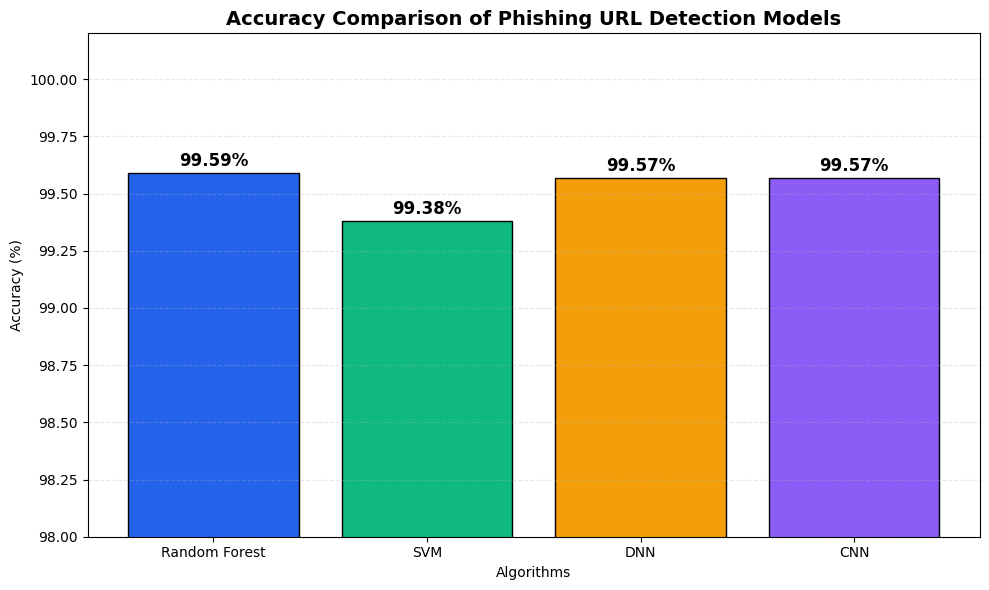

Accuracy comparison graph saved successfully!


In [26]:
# STEP 10: ACCURACY COMPARISON GRAPH

import matplotlib.pyplot as plt

models = ["Random Forest", "SVM", "DNN", "CNN"]

accuracies = [
    rf_url_accuracy * 100,
    svm_url_accuracy * 100,
    dnn_url_accuracy * 100,
    cnn_url_accuracy * 100
]

plt.figure(figsize=(10, 6))

bars = plt.bar(
    models,
    accuracies,
    color=["#2563EB", "#10B981", "#F59E0B", "#8B5CF6"],
    edgecolor="black"
)

# Display accuracy values above bars
for bar, accuracy in zip(bars, accuracies):
    plt.text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height() + 0.03,
        f"{accuracy:.2f}%",
        ha="center",
        fontsize=12,
        fontweight="bold"
    )

plt.title(
    "Accuracy Comparison of Phishing URL Detection Models",
    fontsize=14,
    fontweight="bold"
)

plt.xlabel("Algorithms")
plt.ylabel("Accuracy (%)")

plt.ylim(98, 100.2)
plt.grid(axis="y", linestyle="--", alpha=0.3)

plt.tight_layout()

# Save graph
plt.savefig(
    "model_accuracy_comparison.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("Accuracy comparison graph saved successfully!")

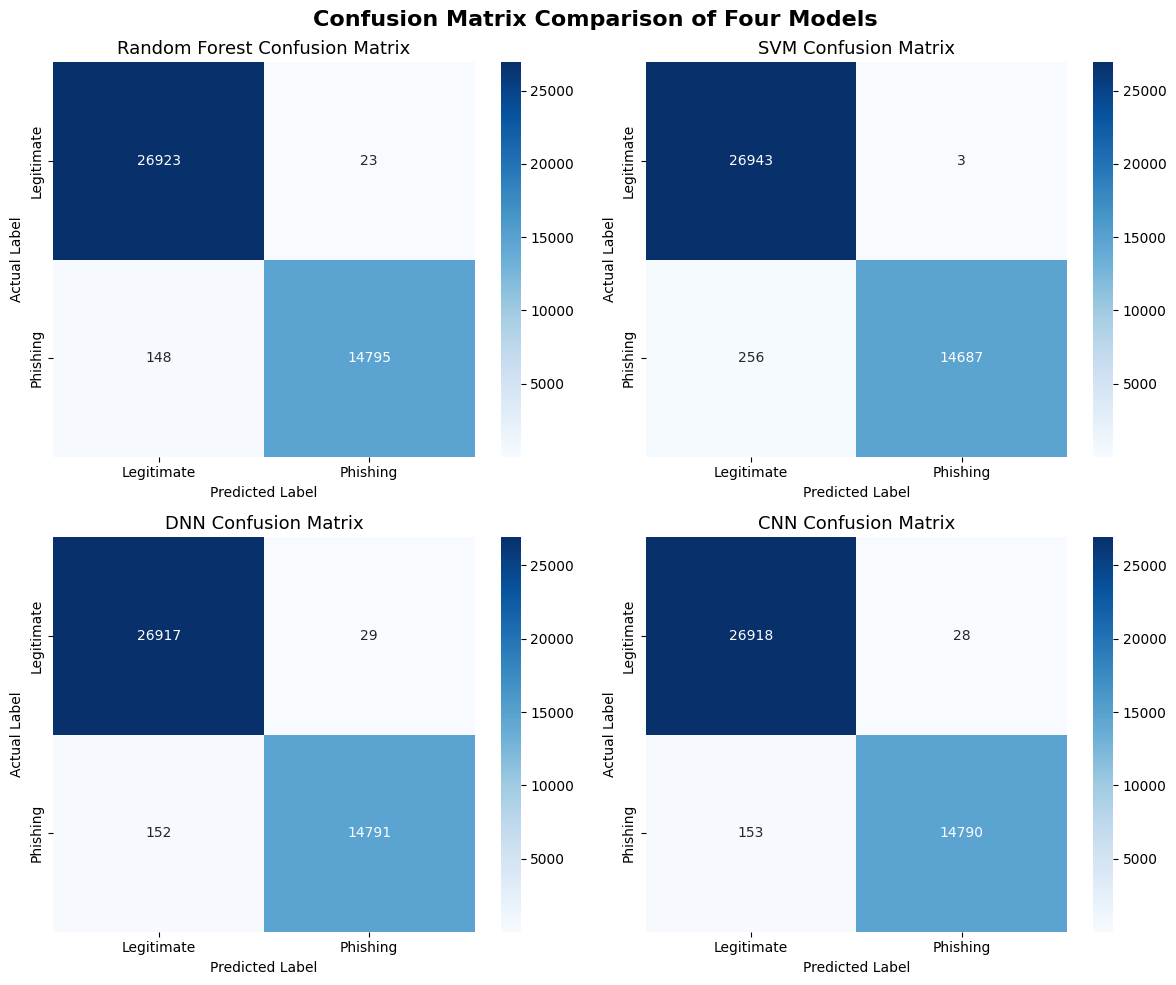

All four confusion matrix heatmaps saved successfully!


In [27]:
# ============================================
# STEP 11: CONFUSION MATRIX HEATMAPS
# ============================================

import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import confusion_matrix

# Model names and their predictions
model_predictions = {
    "Random Forest": rf_url_predictions,
    "SVM": svm_url_predictions,
    "DNN": dnn_url_predictions,
    "CNN": cnn_url_predictions
}

# Create a 2x2 grid of heatmaps
fig, axes = plt.subplots(2, 2, figsize=(12, 10))

for ax, (model_name, predictions) in zip(
    axes.flat, model_predictions.items()
):
    cm = confusion_matrix(y_test_url, predictions)

    sns.heatmap(
        cm,
        annot=True,
        fmt="d",
        cmap="Blues",
        xticklabels=["Legitimate", "Phishing"],
        yticklabels=["Legitimate", "Phishing"],
        ax=ax
    )

    ax.set_title(f"{model_name} Confusion Matrix", fontsize=13)
    ax.set_xlabel("Predicted Label")
    ax.set_ylabel("Actual Label")

plt.suptitle(
    "Confusion Matrix Comparison of Four Models",
    fontsize=16,
    fontweight="bold"
)

plt.tight_layout()

# Save graph
plt.savefig(
    "confusion_matrix_comparison.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("All four confusion matrix heatmaps saved successfully!")

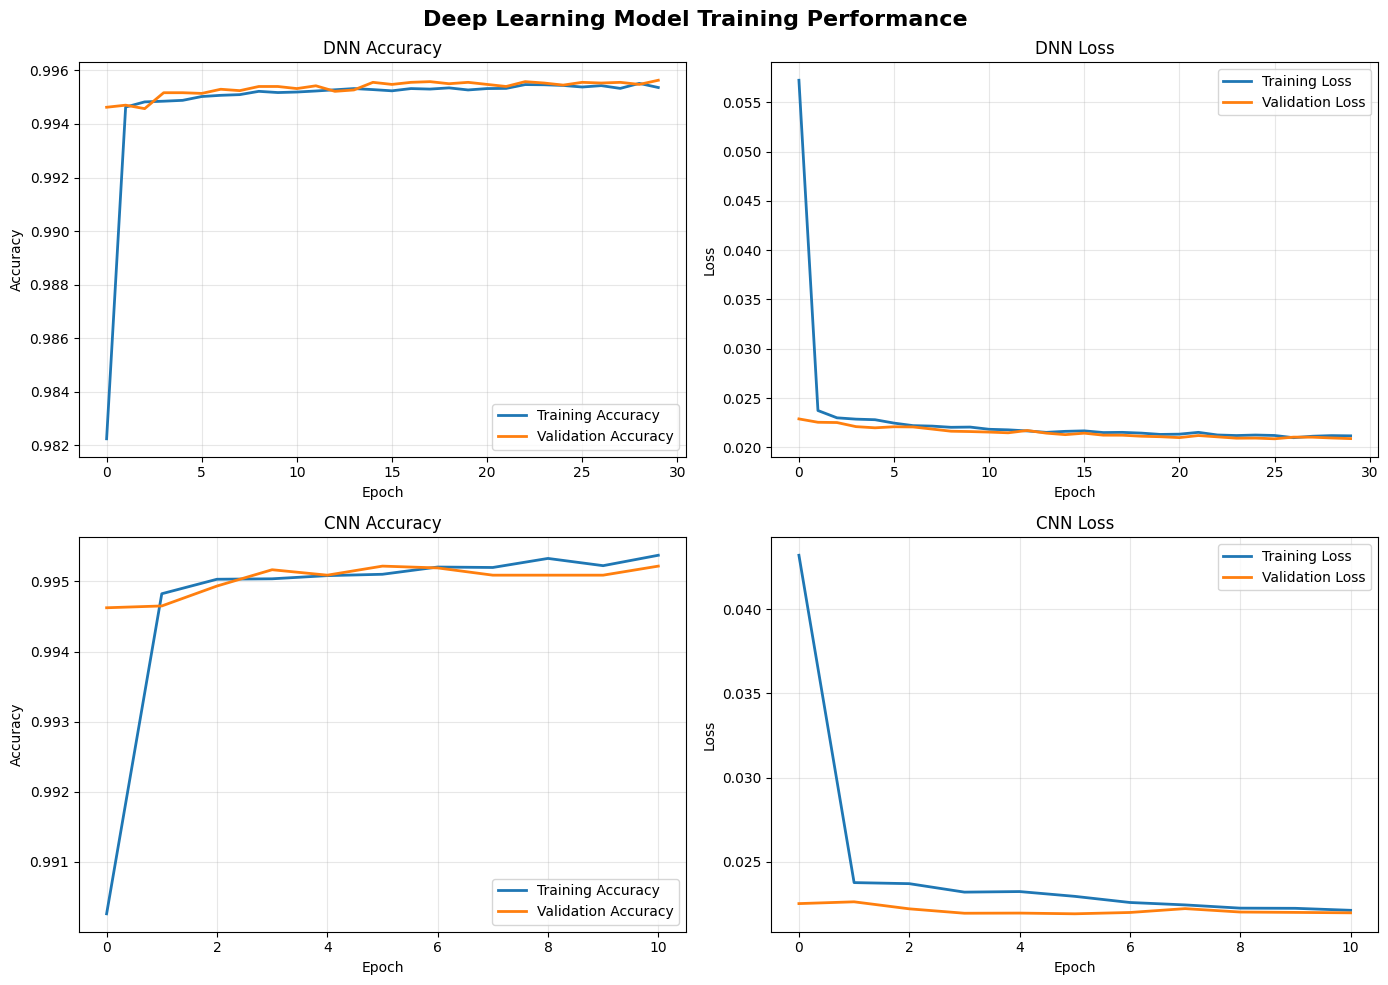

DNN and CNN training graphs saved successfully!


In [28]:
# ============================================
# STEP 12: DNN & CNN TRAINING GRAPHS
# ============================================

import matplotlib.pyplot as plt

# Create 2x2 figure
fig, axes = plt.subplots(2, 2, figsize=(14, 10))

# DNN Accuracy
axes[0, 0].plot(
    dnn_url_history.history["accuracy"],
    label="Training Accuracy",
    linewidth=2
)
axes[0, 0].plot(
    dnn_url_history.history["val_accuracy"],
    label="Validation Accuracy",
    linewidth=2
)
axes[0, 0].set_title("DNN Accuracy")
axes[0, 0].set_xlabel("Epoch")
axes[0, 0].set_ylabel("Accuracy")
axes[0, 0].legend()
axes[0, 0].grid(alpha=0.3)

# DNN Loss
axes[0, 1].plot(
    dnn_url_history.history["loss"],
    label="Training Loss",
    linewidth=2
)
axes[0, 1].plot(
    dnn_url_history.history["val_loss"],
    label="Validation Loss",
    linewidth=2
)
axes[0, 1].set_title("DNN Loss")
axes[0, 1].set_xlabel("Epoch")
axes[0, 1].set_ylabel("Loss")
axes[0, 1].legend()
axes[0, 1].grid(alpha=0.3)

# CNN Accuracy
axes[1, 0].plot(
    cnn_url_history.history["accuracy"],
    label="Training Accuracy",
    linewidth=2
)
axes[1, 0].plot(
    cnn_url_history.history["val_accuracy"],
    label="Validation Accuracy",
    linewidth=2
)
axes[1, 0].set_title("CNN Accuracy")
axes[1, 0].set_xlabel("Epoch")
axes[1, 0].set_ylabel("Accuracy")
axes[1, 0].legend()
axes[1, 0].grid(alpha=0.3)

# CNN Loss
axes[1, 1].plot(
    cnn_url_history.history["loss"],
    label="Training Loss",
    linewidth=2
)
axes[1, 1].plot(
    cnn_url_history.history["val_loss"],
    label="Validation Loss",
    linewidth=2
)
axes[1, 1].set_title("CNN Loss")
axes[1, 1].set_xlabel("Epoch")
axes[1, 1].set_ylabel("Loss")
axes[1, 1].legend()
axes[1, 1].grid(alpha=0.3)

plt.suptitle(
    "Deep Learning Model Training Performance",
    fontsize=16,
    fontweight="bold"
)

plt.tight_layout()

# Save graph
plt.savefig(
    "deep_learning_training_graphs.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("DNN and CNN training graphs saved successfully!")

In [29]:
# ============================================
# STEP 13: SAVE ALL MODELS AND VISUALIZATIONS
# ============================================

import os
import json
import shutil
import joblib

# Create project folder
folder = "phishing_detection_project"
os.makedirs(folder, exist_ok=True)

# Save Machine Learning models
joblib.dump(
    rf_url_model,
    f"{folder}/random_forest.pkl"
)

joblib.dump(
    svm_url_model,
    f"{folder}/svm.pkl"
)

# Save scaler
joblib.dump(
    url_scaler,
    f"{folder}/scaler.pkl"
)

# Save feature names in the correct order
feature_names = list(X_train_url.columns)

with open(f"{folder}/feature_names.json", "w") as f:
    json.dump(feature_names, f, indent=4)

# Save Deep Learning models
dnn_url_model.save(f"{folder}/dnn_model.keras")
cnn_url_model.save(f"{folder}/cnn_model.keras")

# Copy visualization files
graphs = [
    "model_accuracy_comparison.png",
    "confusion_matrix_comparison.png",
    "deep_learning_training_graphs.png"
]

for graph in graphs:
    if os.path.exists(graph):
        shutil.copy(graph, f"{folder}/{graph}")

# Create ZIP file
shutil.make_archive(
    "phishing_detection_project",
    "zip",
    folder
)

print("====================================")
print("ALL MODELS SAVED SUCCESSFULLY!")
print("====================================")

print("\nSaved files:")
for file in os.listdir(folder):
    print("-", file)

print("\nZIP created: phishing_detection_project.zip")

ALL MODELS SAVED SUCCESSFULLY!

Saved files:
- model_accuracy_comparison.png
- deep_learning_training_graphs.png
- svm.pkl
- feature_names.json
- scaler.pkl
- confusion_matrix_comparison.png
- dnn_model.keras
- cnn_model.keras
- random_forest.pkl

ZIP created: phishing_detection_project.zip


In [30]:
from google.colab import files

files.download("phishing_detection_project.zip")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>